# Loan Default Prediction using Logistic Regression

## Industry Problem Statement

### Business Context
Lending institutions (banks, NBFCs, and fintech lenders) face significant financial risk due to loan defaults. When borrowers fail to repay, the institution incurs losses in the form of non-performing assets (NPAs), increased provisioning requirements, higher cost of capital, and reduced profitability. In competitive lending markets, the ability to accurately assess credit risk at the time of loan application is a critical capability that directly impacts portfolio quality and long-term business sustainability.

### Problem Definition
The organization needs a reliable, scalable, and explainable predictive system that can estimate the probability of a borrower defaulting on a loan. The system should use applicant-level demographic, financial, employment, and loan-related information available at the application stage to classify each applicant as either:

- **Likely to Default** (high risk), or  
- **Likely to Repay** (low risk)

### Business Objectives
1. **Reduce Credit Losses**: Identify high-risk applicants early so that loan amounts, interest rates, or approval decisions can be adjusted accordingly.
2. **Improve Approval Efficiency**: Enable faster and more consistent credit decisions while maintaining risk control.
3. **Optimize Portfolio Quality**: Support risk-based pricing and portfolio management strategies.
4. **Maintain Fairness and Explainability**: Ensure the model is interpretable so that credit decisions can be justified to regulators, auditors, and customers.

### Success Criteria
- Strong ability to distinguish between defaulting and non-defaulting applicants (ROC-AUC and Recall on the default class).
- Predictions generated using only information available at the time of application.
- Suitable for integration into existing credit decision engines or underwriting workflows.
- Model outputs (probability of default) support threshold-based decision rules that can be tuned according to the institution’s risk appetite.

### Dataset
- **Source**: Kaggle – Loan Default Prediction Dataset (https://www.kaggle.com/datasets/nikhil1e9/loan-default)
- **Records**: 255,347 loan applications
- **Target**: `Default` (0 = No Default, 1 = Default)
- **Default Rate**: ~11.61% (imbalanced)

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Dataset

In [2]:
# Load the dataset
df = pd.read_csv('Loan_default.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
df.head()

Dataset shape: (255347, 18)

Columns: ['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [3]:
for i in df.select_dtypes(include=object).columns:
    print(df[i].unique())


<ArrowStringArray>
['I38PQUQS96', 'HPSK72WA7R', 'C1OZ6DPJ8Y', 'V2KKSFM3UN', 'EY08JDHTZP',
 'A9S62RQ7US', 'H8GXPAOS71', '0HGZQKJ36W', '1R0N3LGNRJ', 'CM9L1GTT2P',
 ...
 'DSL4O0KAWD', '6V8S5IUS63', 'O6SWO6CBGB', '48LOOK4VR1', 'AKXAXQN7PG',
 '8C6S86ESGC', '98R4KDHNND', 'XQK1UUUNGP', 'JAO28CPL4H', 'ZTH91CGL0B']
Length: 255347, dtype: str
<ArrowStringArray>
['Bachelor's', 'Master's', 'High School', 'PhD']
Length: 4, dtype: str
<ArrowStringArray>
['Full-time', 'Unemployed', 'Self-employed', 'Part-time']
Length: 4, dtype: str
<ArrowStringArray>
['Divorced', 'Married', 'Single']
Length: 3, dtype: str
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
<ArrowStringArray>
['Other', 'Auto', 'Business', 'Home', 'Education']
Length: 5, dtype: str
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str


In [4]:
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [5]:
df.duplicated().sum()

np.int64(0)

## 3. Exploratory Data Analysis (EDA)

In [6]:
# Basic info
print("Dataset Info:")
print("-" * 50)
df.info()

print("\n\nMissing Values:")
print("-" * 50)
print(df.isnull().sum())

Dataset Info:
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  str    
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  str    
 11  EmploymentType  255347 non-null  str    
 12  MaritalStatus   255347 non-null  str    
 13  HasMortgage     255347 non-null  str    
 14  HasDependents   255347 non-null  str    
 15  LoanPurpose     255347 non-null  str    
 16  Ha

In [7]:
# Statistical summary of numerical features
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,255347.0,43.498306,14.990258,18.0,31.00,43.00,56.00,69.0
Income,255347.0,82499.304597,38963.013729,15000.0,48825.50,82466.00,116219.00,149999.0
LoanAmount,255347.0,127578.865512,70840.706142,5000.0,66156.00,127556.00,188985.00,249999.0
CreditScore,255347.0,574.264346,158.903867,300.0,437.00,574.00,712.00,849.0
MonthsEmployed,255347.0,59.541976,34.643376,0.0,30.00,60.00,90.00,119.0
NumCreditLines,255347.0,2.501036,1.117018,1.0,2.00,2.00,3.00,4.0
InterestRate,255347.0,13.492773,6.636443,2.0,7.77,13.46,19.25,25.0
LoanTerm,255347.0,36.025894,16.969330,12.0,24.00,36.00,48.00,60.0
DTIRatio,255347.0,0.500212,0.230917,0.1,0.30,0.50,0.70,0.9
Default,255347.0,0.116128,0.320379,0.0,0.00,0.00,0.00,1.0


<Axes: xlabel='Default'>

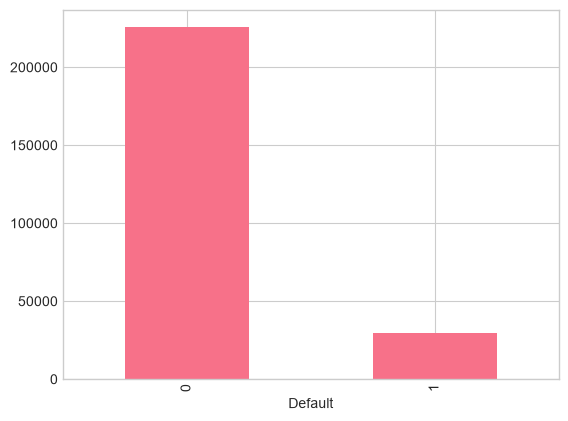

In [8]:
df['Default'].value_counts().plot(kind='bar')

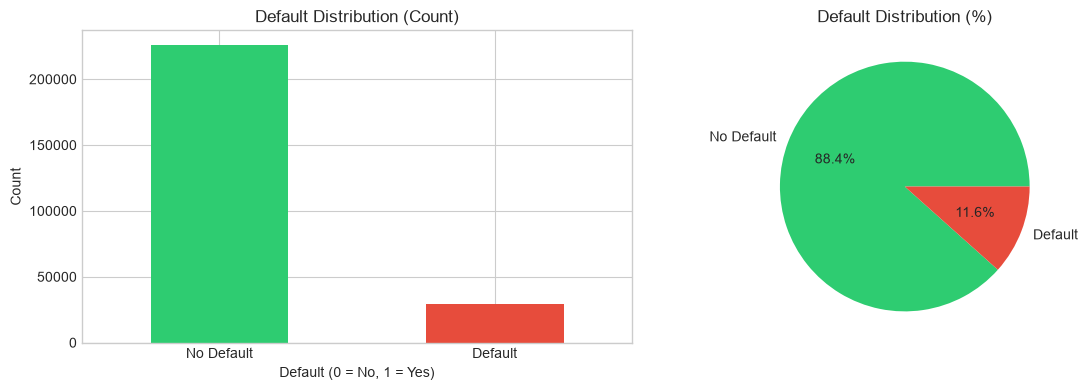

In [9]:
# Target distribution plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['Default'].value_counts().plot(kind='bar', ax=axes[0], color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Default Distribution (Count)')
axes[0].set_xlabel('Default (0 = No, 1 = Yes)')
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(['No Default', 'Default'], rotation=0)

df['Default'].value_counts(normalize=True).plot(kind='pie', ax=axes[1], 
                                                 autopct='%1.1f%%',
                                                 colors=['#2ecc71', '#e74c3c'],
                                                 labels=['No Default', 'Default'])
axes[1].set_title('Default Distribution (%)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

In [10]:
df.select_dtypes(exclude='str').columns

Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Default'],
      dtype='str')

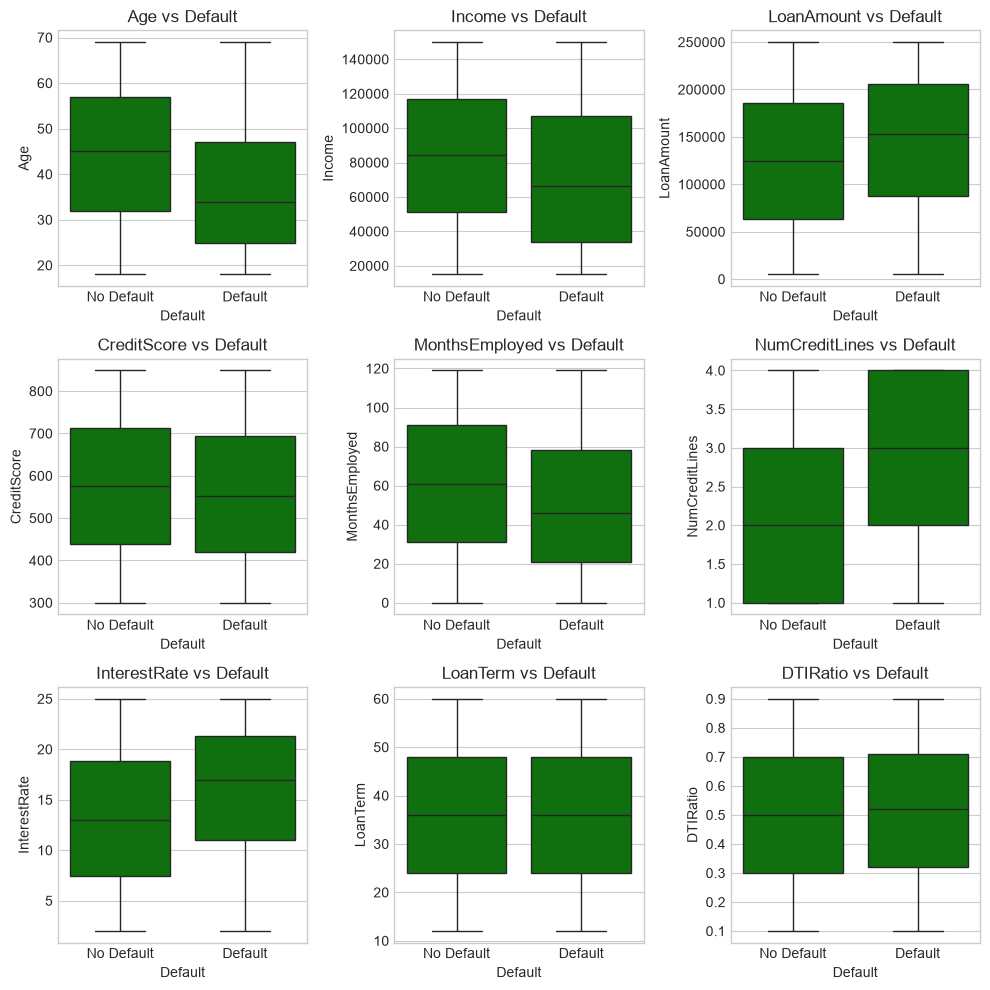

In [11]:
numerical_cols=['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']

fig, axs= plt.subplots(3,3,figsize=(10,10))
axs= axs.flatten()
for index, column_name in enumerate(numerical_cols):
    sns.boxplot(data=df,y=column_name,x='Default',ax=axs[index], color='g')
    axs[index].set_title(f'{column_name} vs Default')
    axs[index].set_xticklabels(['No Default','Default'])
    plt.tight_layout()

In [12]:
# correlation

plt.figure(figsize=(10,8))
df[numerical_cols+['Default']].corr()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
Age,1.000000,-0.001244,-0.002213,-0.000548,-0.000341,-0.000890,-0.001127,0.000263,-0.004689,-0.167783
Income,-0.001244,1.000000,-0.000865,-0.001430,0.002675,-0.002016,-0.002303,-0.000998,0.000205,-0.099119
LoanAmount,-0.002213,-0.000865,1.000000,0.001261,0.002817,0.000794,-0.002291,0.002538,0.001122,0.086659
CreditScore,-0.000548,-0.001430,0.001261,1.000000,0.000613,0.000016,0.000436,0.001130,-0.001039,-0.034166
MonthsEmployed,-0.000341,0.002675,0.002817,0.000613,1.000000,0.001267,0.000096,-0.001166,0.001765,-0.097374
NumCreditLines,-0.000890,-0.002016,0.000794,0.000016,0.001267,1.000000,-0.000297,-0.000226,-0.000586,0.028330
InterestRate,-0.001127,-0.002303,-0.002291,0.000436,0.000096,-0.000297,1.000000,0.000892,0.000575,0.131273
LoanTerm,0.000263,-0.000998,0.002538,0.001130,-0.001166,-0.000226,0.000892,1.000000,0.002273,0.000545
DTIRatio,-0.004689,0.000205,0.001122,-0.001039,0.001765,-0.000586,0.000575,0.002273,1.000000,0.019236
Default,-0.167783,-0.099119,0.086659,-0.034166,-0.097374,0.028330,0.131273,0.000545,0.019236,1.000000


<Figure size 1000x800 with 0 Axes>

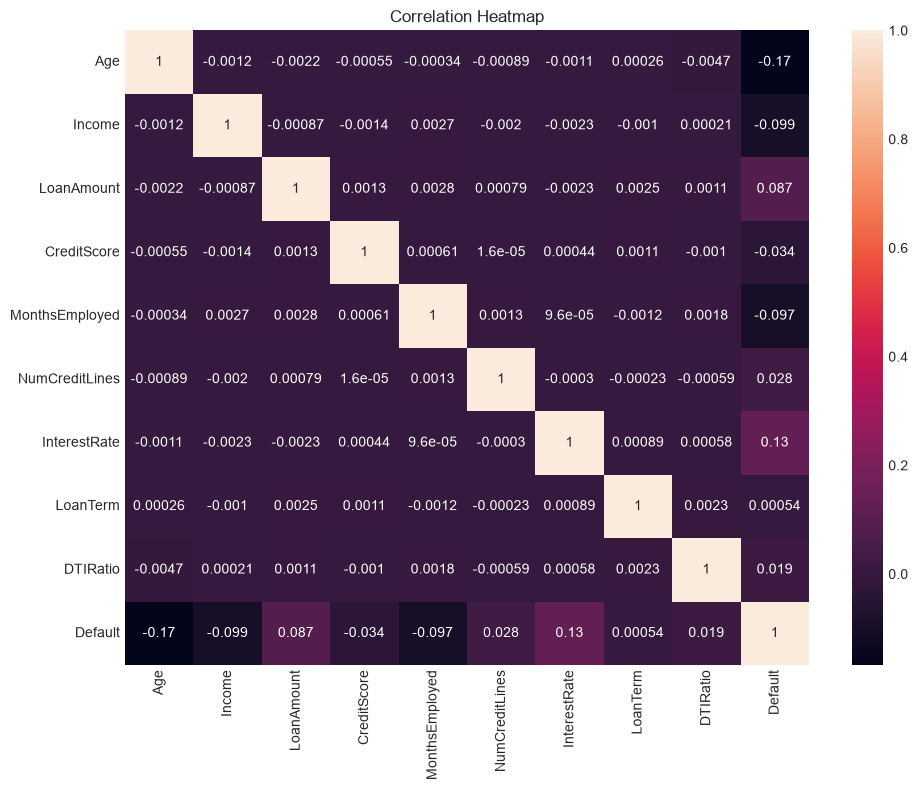

In [13]:
plt.figure(figsize=(10,8))
sns.heatmap(df[numerical_cols+['Default']].corr(),annot=True)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [14]:
# data preprocessing

In [15]:
df.drop('LoanID', axis=1, inplace=True)

In [16]:
X= df.drop('Default',axis=1)
Y= df['Default']

In [17]:
X

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No
255343,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No
255344,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes
255345,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No


In [18]:
categorical_column=X.select_dtypes(include='str').columns.to_list()
numerical_column=X.select_dtypes(exclude='str').columns.to_list()
label_encoders={}
print(categorical_column)
for col in categorical_column:
    le= LabelEncoder()
    X[col]=le.fit_transform(X[col].astype(str))
    print(f'''encoded {col}: {dict(zip(le.classes_, 
    le.transform(le.classes_)))}''')

['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']
encoded Education: {"Bachelor's": np.int64(0), 'High School': np.int64(1), "Master's": np.int64(2), 'PhD': np.int64(3)}
encoded EmploymentType: {'Full-time': np.int64(0), 'Part-time': np.int64(1), 'Self-employed': np.int64(2), 'Unemployed': np.int64(3)}
encoded MaritalStatus: {'Divorced': np.int64(0), 'Married': np.int64(1), 'Single': np.int64(2)}
encoded HasMortgage: {'No': np.int64(0), 'Yes': np.int64(1)}
encoded HasDependents: {'No': np.int64(0), 'Yes': np.int64(1)}
encoded LoanPurpose: {'Auto': np.int64(0), 'Business': np.int64(1), 'Education': np.int64(2), 'Home': np.int64(3), 'Other': np.int64(4)}
encoded HasCoSigner: {'No': np.int64(0), 'Yes': np.int64(1)}


In [19]:
X

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner
0,56,85994,50587,520,80,4,15.23,36,0.44,0,0,0,1,1,4,1
1,69,50432,124440,458,15,1,4.81,60,0.68,2,0,1,0,0,4,1
2,46,84208,129188,451,26,3,21.17,24,0.31,2,3,0,1,1,0,0
3,32,31713,44799,743,0,3,7.07,24,0.23,1,0,1,0,0,1,0
4,60,20437,9139,633,8,4,6.51,48,0.73,0,3,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,19,37979,210682,541,109,4,14.11,12,0.85,0,0,1,0,0,4,0
255343,32,51953,189899,511,14,2,11.55,24,0.21,1,1,0,0,0,3,0
255344,56,84820,208294,597,70,3,5.29,60,0.50,1,2,1,1,1,0,1
255345,42,85109,60575,809,40,1,20.90,48,0.44,1,1,2,1,1,4,0


In [20]:
x_train, x_test,y_train, y_test= train_test_split(
    X,Y,test_size=0.2,random_state=22
)

In [21]:
scaler= StandardScaler()
X_train_scaled=x_train.copy()
X_test_scaled=x_test.copy()
X_train_scaled[numerical_cols]=scaler.fit_transform(x_train[numerical_column])
X_test_scaled[numerical_cols]=scaler.fit_transform(x_test[numerical_column])

In [22]:
lr= LogisticRegression(class_weight='balanced',
max_iter=200,solver='lbfgs')
lr.fit(X_train_scaled,y_train)
y_pred=lr.predict(X_test_scaled)
y_pred_proba=lr.predict(X_test_scaled)

In [23]:

from sklearn.metrics import (ConfusionMatrixDisplay,confusion_matrix,
classification_report, accuracy_score,
precision_score,recall_score, roc_curve, roc_auc_score, f1_score)

In [24]:
print(f'accuracy_score: {accuracy_score(y_test,y_pred)}')
print(f'precision_score: {precision_score(y_test,y_pred)}')
print(f'recall_score: {recall_score(y_test,y_pred)}')
print(f'f1 score: {f1_score(y_test,y_pred_proba)}')
print(f'roc auc score: {roc_auc_score(y_test,y_pred_proba)}')

accuracy_score: 0.6735656941452908
precision_score: 0.2170673712021136
recall_score: 0.6890305266689031
f1 score: 0.33013219753284845
roc auc score: 0.6802761039835603


In [25]:
print(classification_report(y_test,y_pred, 
target_names=['No default', 'Default']))

              precision    recall  f1-score   support

  No default       0.94      0.67      0.78     45108
     Default       0.22      0.69      0.33      5962

    accuracy                           0.67     51070
   macro avg       0.58      0.68      0.56     51070
weighted avg       0.86      0.67      0.73     51070



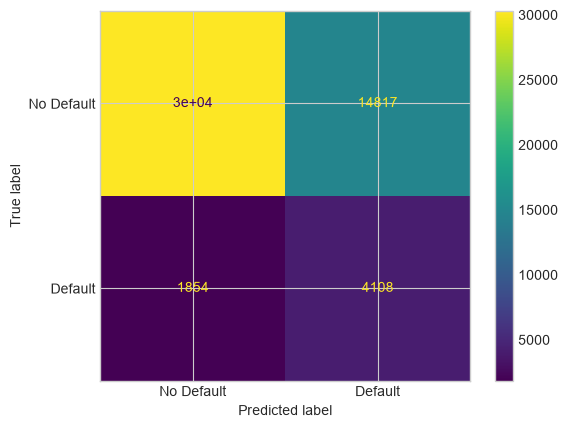

In [26]:
cm= confusion_matrix(y_test,y_pred)

dis= ConfusionMatrixDisplay(confusion_matrix=cm,
display_labels=['No Default', 'Default'])
dis.plot()
plt.show()

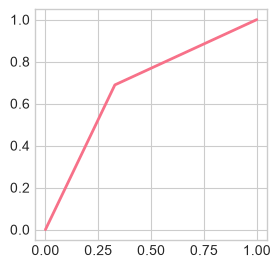

In [27]:
fpr, tpr, thresholds= roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(3,3))
plt.plot(fpr, tpr, lw=2)

In [28]:
lr.coef_[0]



array([-0.5909477 , -0.31143532,  0.28522599, -0.121901  , -0.34008807,
        0.09304868,  0.45881066, -0.00180969,  0.06580753, -0.07015296,
        0.12791425, -0.03001913, -0.1569195 , -0.23836668, -0.02906108,
       -0.26253872])

In [29]:
coef_df= pd.DataFrame({
    'Columns':x_train.columns,
    'cofficient':lr.coef_[0]
}).sort_values(by='cofficient', key=abs,ascending=False)

In [30]:
coef_df

,Columns,cofficient
0,Age,-0.590948
6,InterestRate,0.458811
4,MonthsEmployed,-0.340088
1,Income,-0.311435
2,LoanAmount,0.285226
15,HasCoSigner,-0.262539
13,HasDependents,-0.238367
12,HasMortgage,-0.156919
10,EmploymentType,0.127914
3,CreditScore,-0.121901


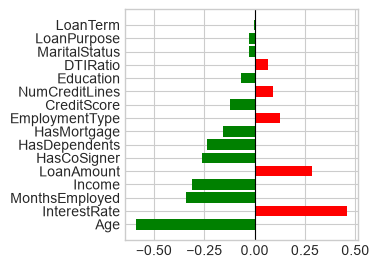

In [31]:
plt.figure(figsize=(3,3))
color=['r' if c >0 else 'g' for c in coef_df['cofficient']]
plt.barh(coef_df['Columns'], coef_df['cofficient'],color=color)
plt.axvline(x=0 , color='black', linewidth=0.8, linestyle='-')
plt.show()

In [ ]:
x_test.iloc[:2,:]

2

In [39]:
#from statsmodels.stats.nonparametric import jonckheere_terpstra
import joblib

joblib.dump(lr,'logistic_regression.pkl')

['logistic_regression.pkl']

In [40]:
model=joblib.load('logistic_regression.pkl')

In [48]:
model.predict(x_test.iloc[:2,:])

array([1, 1])

In [32]:
X_train_scaled

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner
61239,-0.033318,-0.509449,-0.839543,1.428643,-1.286558,0.446829,0.634825,0.705380,0.821330,2,3,2,1,1,0,1
205826,1.233977,-0.307444,0.120613,0.471289,-1.084489,1.342631,1.091035,-0.001988,1.384284,1,0,2,1,0,3,1
72979,-0.767015,1.355305,-0.774615,-0.001089,1.224866,1.342631,-1.542335,-0.001988,-1.300570,0,0,1,0,1,4,0
155879,0.366881,0.376375,-0.573266,-1.638668,0.560927,0.446829,-0.117996,-0.001988,1.297675,0,1,0,1,0,2,0
154184,0.833779,0.721789,-0.801580,1.057038,-0.680352,-1.344776,-0.334809,-0.001988,-0.217968,3,3,1,1,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24932,-0.767015,1.102818,0.739144,-0.309710,-0.305082,-1.344776,1.402703,-1.416724,0.648114,0,0,1,0,0,0,1
162752,-1.500712,1.001366,0.233654,1.667981,0.560927,0.446829,-0.327281,0.705380,0.171769,3,1,2,0,1,0,1
226092,0.033382,0.884610,1.477226,0.660241,-0.738086,-0.448973,-0.390518,-1.416724,1.211067,1,3,2,0,1,3,1
252036,0.033382,-0.154842,1.376693,0.269741,1.051665,0.446829,-0.432676,1.412748,0.821330,1,1,2,1,0,3,0


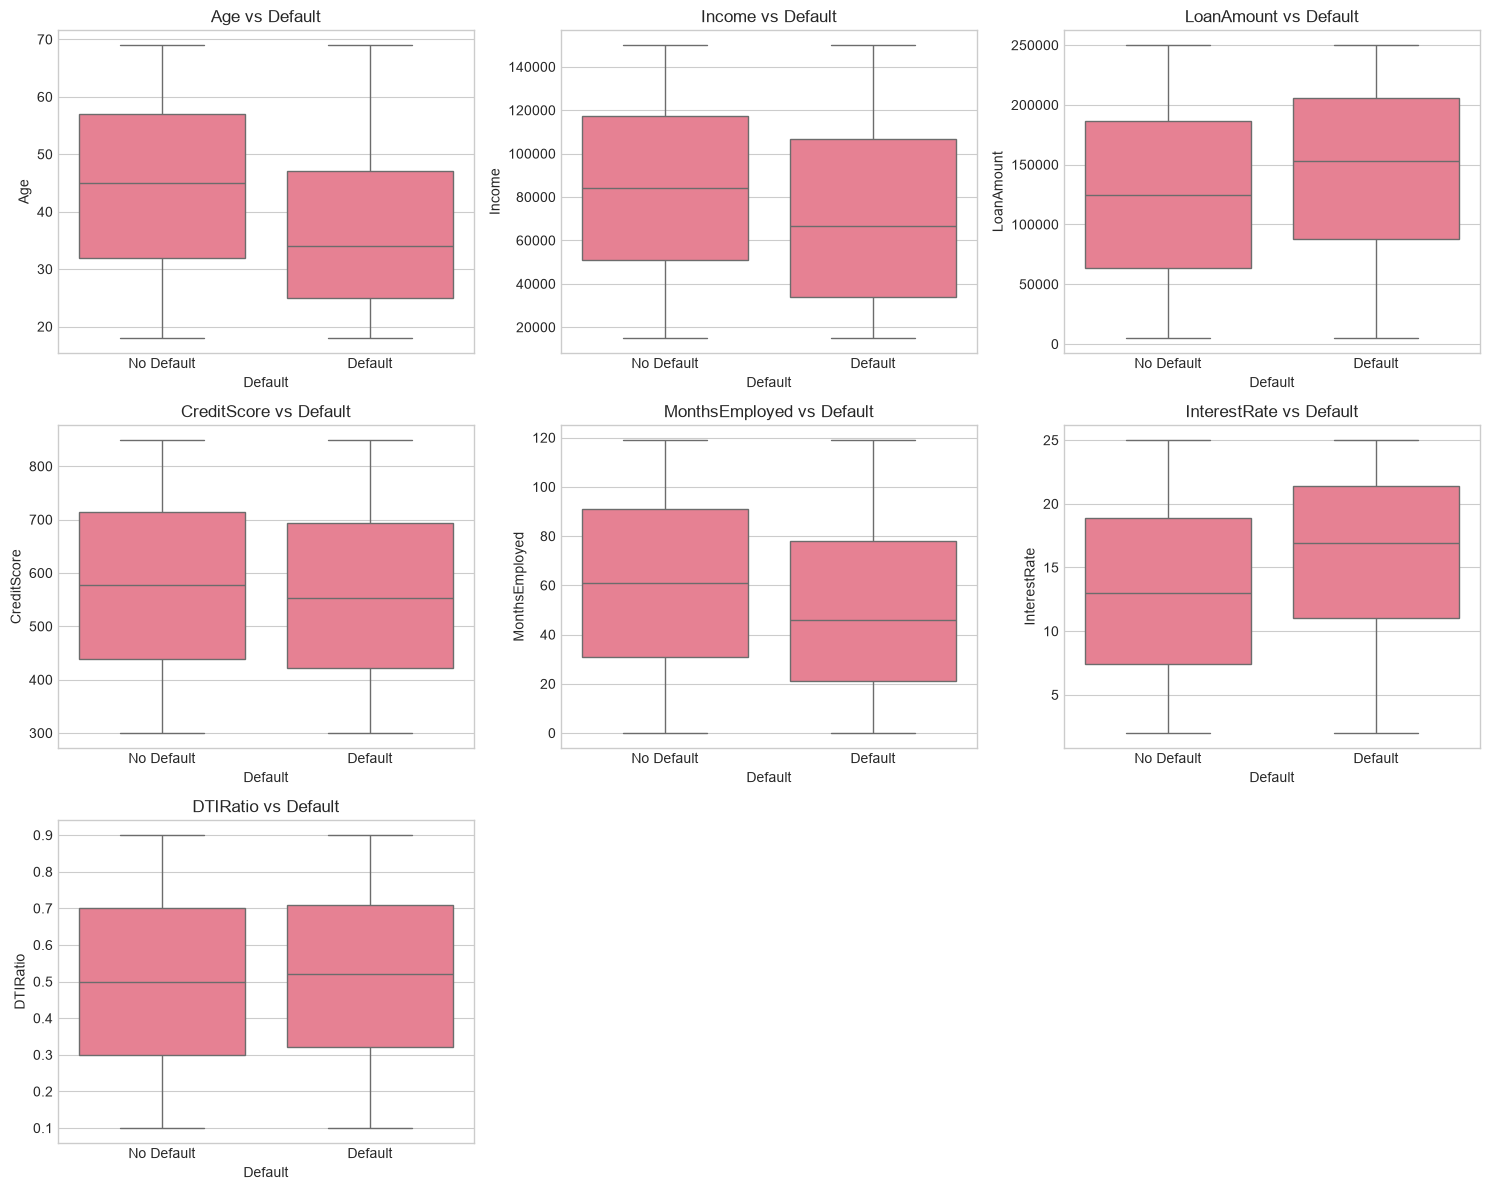

In [33]:
# Numerical features distribution by Default
numerical_features = ['Age', 'Income', 'LoanAmount', 'CreditScore', 
                      'MonthsEmployed', 'InterestRate', 'DTIRatio']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(numerical_features):
    sns.boxplot(x='Default', y=col, data=df, ax=axes[i])
    axes[i].set_title(f'{col} vs Default')
    axes[i].set_xticklabels(['No Default', 'Default'])

# Hide unused subplots
for j in range(len(numerical_features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

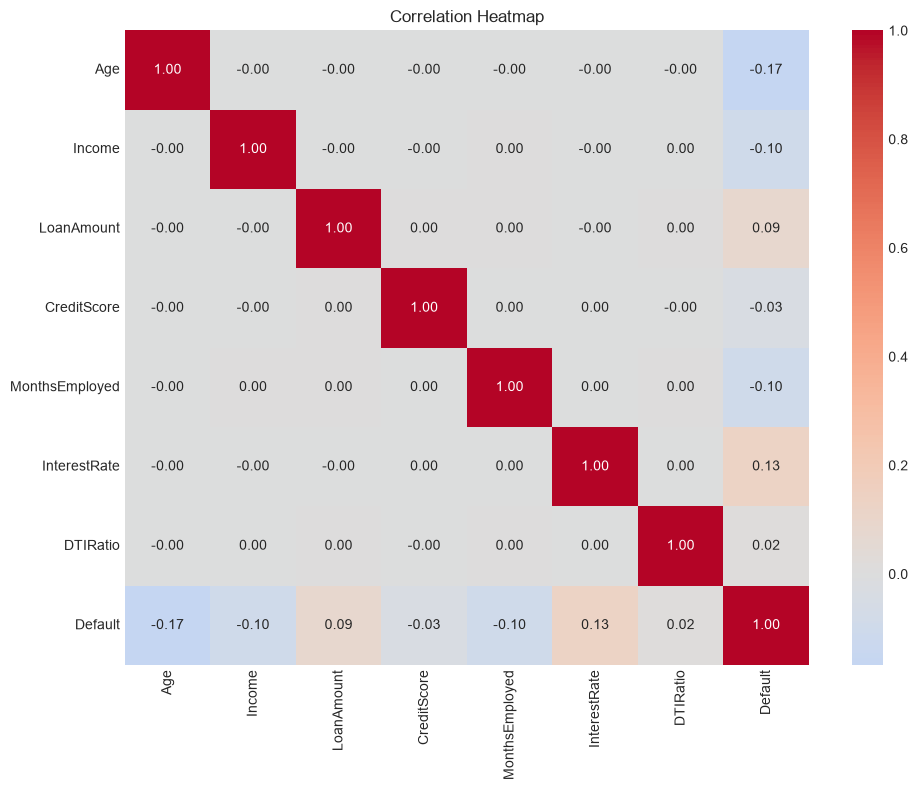

In [34]:
# Correlation heatmap of numerical features
plt.figure(figsize=(10, 8))
corr = df[numerical_features + ['Default']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

## 4. Data Preprocessing

In [35]:
# Drop LoanID (not useful for modeling)
df_model = df.drop(columns=['LoanID'])

# Separate features and target
X = df_model.drop(columns=['Default'])
y = df_model['Default']

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

KeyError: "['LoanID'] not found in axis"

In [ ]:
# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Categorical columns:", categorical_cols)
print("\nNumerical columns:", numerical_cols)

In [ ]:
# Encode categorical variables using Label Encoding
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    label_encoders[col] = le
    print(f"Encoded {col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")

In [ ]:
# Train-Test Split (80-20) with stratification to maintain class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")
print(f"\nTrain Default Rate: {y_train.mean()*100:.2f}%")
print(f"Test Default Rate:  {y_test.mean()*100:.2f}%")

In [ ]:
# Feature Scaling (StandardScaler) - only on numerical features
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("Feature scaling completed.")
X_train_scaled.head()

## 5. Build Logistic Regression Model

We use `class_weight='balanced'` to handle the class imbalance (only ~11.6% defaults).

In [ ]:
# Initialize and train Logistic Regression model
model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced',   # Handles class imbalance
    solver='lbfgs'
)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

## 6. Model Evaluation

In [ ]:
# Predictions
y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("=" * 50)
print("MODEL PERFORMANCE METRICS")
print("=" * 50)
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print("=" * 50)

In [ ]:
# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Default (0)', 'Default (1)']))

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                               display_labels=['No Default', 'Default'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

print(f"True Negatives (TN) : {cm[0,0]}")
print(f"False Positives (FP): {cm[0,1]}")
print(f"False Negatives (FN): {cm[1,0]}")
print(f"True Positives (TP) : {cm[1,1]}")

In [ ]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='#3498db', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Feature Importance (Model Coefficients)

In Logistic Regression, the magnitude and sign of coefficients indicate the strength and direction of each feature’s influence on the probability of default.

In [ ]:
# Extract and display coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', key=abs, ascending=False)

print("Feature Importance (sorted by absolute coefficient value):")
print("=" * 60)
print(coef_df.to_string(index=False))
print("=" * 60)
print("\nInterpretation:")
print("- Positive coefficient → Increases probability of Default")
print("- Negative coefficient → Decreases probability of Default")
print("- Larger absolute value → Stronger influence on the prediction")

In [ ]:
# Visualize feature importance
plt.figure(figsize=(10, 6))
colors = ['#e74c3c' if c > 0 else '#2ecc71' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
plt.xlabel('Coefficient Value')
plt.title('Logistic Regression Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 8. Sample Predictions

In [ ]:
# Show sample predictions from the test set
sample_results = pd.DataFrame({
    'Actual': y_test.values[:15],
    'Predicted': y_pred[:15],
    'Probability_of_Default': np.round(y_pred_proba[:15], 4)
})

print("Sample Predictions (first 15 records from Test Set):")
print(sample_results.to_string(index=False))

## 9. Key Insights & Recommendations

### Model Performance Summary
- **ROC-AUC ≈ 0.75**: The model has decent discrimination ability.
- **Recall ≈ 0.70**: Captures ~70% of actual defaults (important for risk management).
- **Precision is lower** due to class imbalance and the use of balanced class weights (trade-off for higher recall).

### Most Influential Features
| Feature          | Impact on Default Risk |
|------------------|------------------------|
| Age              | Higher age → Lower risk |
| InterestRate     | Higher rate → Higher risk |
| MonthsEmployed   | Longer employment → Lower risk |
| Income           | Higher income → Lower risk |
| LoanAmount       | Larger loan → Higher risk |
| HasCoSigner      | Presence of co-signer → Lower risk |

### Business Recommendations
1. **Use Probability Threshold Tuning**: Instead of the default 0.5 threshold, choose a threshold based on the institution’s risk appetite (e.g., higher threshold for stricter approval).
2. **Risk-Based Pricing**: Use the predicted probability of default to set interest rates or loan limits.
3. **Further Improvements**:
   - Try advanced models (Random Forest, XGBoost, LightGBM)
   - Apply SMOTE or other oversampling techniques
   - Perform hyperparameter tuning and cross-validation
   - Add interaction features or domain-specific engineered features
4. **Model Monitoring**: Once deployed, continuously monitor for data drift and performance degradation.

---

